# Domain-Adaptive Emotion Analysis — Team Project Notebook
**Target (domain):** ISEAR (`dalopeza/isear-dataset`) — first-person narratives, 7 emotions
**Source (general):** `dimonyara/additional-dataset-for-emotions` — short social-style text, raw labels: fun, sadness, anger, worry, love, surprise

**Shared 4-class label space:** joy, sadness, anger, fear. `fun`→joy and `worry`→fear are deliberate semantic merges (closest proxies); `love` and `surprise` are excluded. Document this in the report.

**Domain shift:** genre/style (short social text → longer narrative), not industry-vertical.

**Runtime:** `Runtime > Change runtime type > T4 GPU` before Section 5. Run cells top to bottom. Every section rebuilds from the data it needs, so a restart just means re-running from Section 1.

## 0. Setup

In [2]:
%pip -q install transformers datasets accelerate scikit-learn kagglehub seaborn

import os, re, glob, gc, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("GPU available:", torch.cuda.is_available())

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Note: you may need to restart the kernel to use updated packages.
GPU available: True


## 1. Load data
ISEAR is stored as three CSVs (train/val/test); we combined 3 of
them into one dataframe and do our own split later.

In [3]:
# ISEAR (target): combine the three provided splits
import kagglehub
isear_path = kagglehub.dataset_download("dalopeza/isear-dataset")
df_isear_raw = pd.concat(
    [pd.read_csv(os.path.join(isear_path, f)) for f in ["train_data.csv", "val_data.csv", "test_data.csv"]],
    ignore_index=True)

# Additional emotions dataset (source)
extra_path = kagglehub.dataset_download("dimonyara/additional-dataset-for-emotions")
df_extra_raw = pd.read_csv(glob.glob(os.path.join(extra_path, "*.csv"))[0])

# Standardise to text / label
df_target = df_isear_raw[["text", "emotion"]].rename(columns={"emotion": "label"}).copy()
df_source = df_extra_raw[["content", "sentiment"]].rename(columns={"content": "text", "sentiment": "label"}).copy()
for d in (df_target, df_source):
    d["label"] = d["label"].astype(str).str.strip().str.lower()

print("Target (ISEAR):", df_target.shape, "| Source:", df_source.shape)
print(df_target["label"].value_counts(), "\n")
print(df_source["label"].value_counts())

c:\Users\jorda\.conda\envs\ml-gpu\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 309k/309k [00:00<00:00, 434kB/s]

Extracting files...


100%|██████████| 719k/719k [00:00<00:00, 750kB/s]

Extracting files...
Target (ISEAR): (7534, 2) | Source: (20000, 2)
label
joy        1088
anger      1086
fear       1084
sadness    1080
disgust    1070
guilt      1065
shame      1061
Name: count, dtype: int64 

label
fun         6761
sadness     5797
anger       2709
worry       2373
love        1641
surprise     719
Name: count, dtype: int64


## 2. Exploratory data analysis (raw data, all original labels)

--- Source (general) ---
rows: 20000 | missing text: 0 | classes: 6
mean words: 19.1 | median: 17.0 | max: 66 

--- Target (ISEAR) ---
rows: 7534 | missing text: 0 | classes: 7
mean words: 21.5 | median: 19.0 | max: 57 



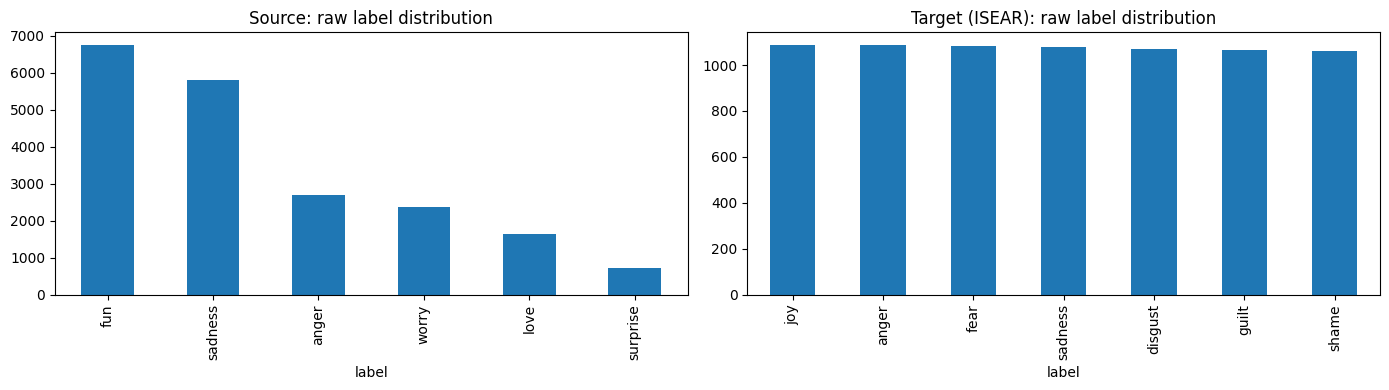

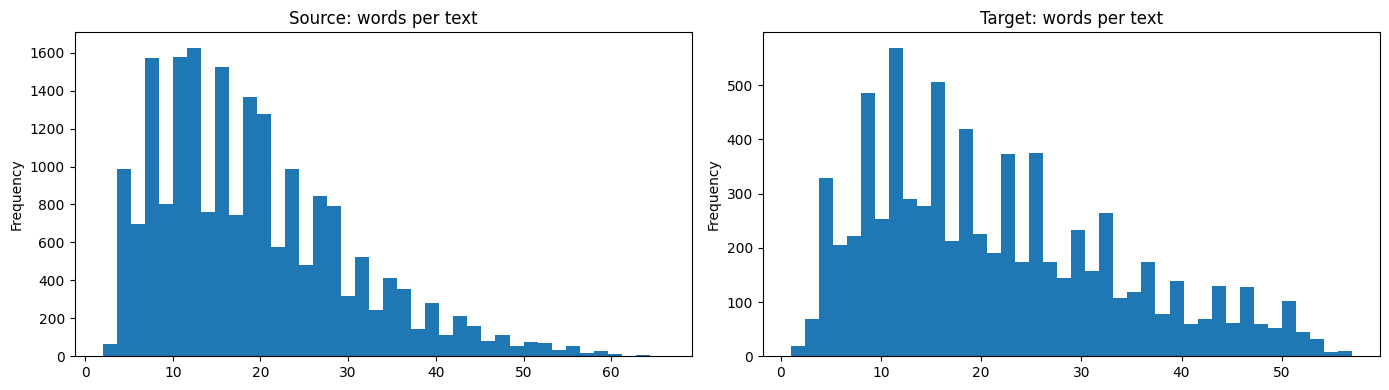

In [4]:
for name, d in [("Source (general)", df_source), ("Target (ISEAR)", df_target)]:
    lengths = d["text"].dropna().astype(str).str.split().apply(len)
    print(f"--- {name} ---")
    print("rows:", len(d), "| missing text:", d["text"].isna().sum(), "| classes:", d["label"].nunique())
    print("mean words:", round(lengths.mean(), 1), "| median:", lengths.median(), "| max:", lengths.max(), "\n")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df_source["label"].value_counts().plot(kind="bar", ax=ax[0], title="Source: raw label distribution")
df_target["label"].value_counts().plot(kind="bar", ax=ax[1], title="Target (ISEAR): raw label distribution")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df_source["text"].astype(str).str.split().apply(len).plot(kind="hist", bins=40, ax=ax[0], title="Source: words per text")
df_target["text"].astype(str).str.split().apply(len).plot(kind="hist", bins=40, ax=ax[1], title="Target: words per text")
plt.tight_layout(); plt.show()

## 3. Clean, map labels, de-duplicate, split
Order matters: duplicates are removed **before** splitting, source rows that also appear in the target are dropped, and the target test set is created once and never used for training, tuning or checkpoint selection.

In [5]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"[^a-z\s']", " ", t)
    return re.sub(r"\s+", " ", t).strip()

LABEL_MAP = {
    "joy": "joy", "fun": "joy",
    "sadness": "sadness",
    "anger": "anger",
    "fear": "fear", "worry": "fear",
}   # love, surprise (source) and disgust, shame, guilt (target) are excluded

def prepare(df):
    df = df.copy()
    df["clean"] = df["text"].apply(clean_text)
    df["label_mapped"] = df["label"].map(LABEL_MAP)
    df = df.dropna(subset=["label_mapped"])
    df = df[df["clean"].str.len() > 0]
    conflicts = df.groupby("clean")["label_mapped"].nunique()
    df = df[~df["clean"].isin(conflicts[conflicts > 1].index)]     # same text, different labels
    return df.drop_duplicates(subset="clean").reset_index(drop=True)

df_source = prepare(df_source)
df_target = prepare(df_target)
df_source = df_source[~df_source["clean"].isin(set(df_target["clean"]))].reset_index(drop=True)  # no source/target overlap

common_labels = sorted(set(df_source["label_mapped"]) & set(df_target["label_mapped"]))
assert len(common_labels) >= 4, f"Only {len(common_labels)} shared classes: check LABEL_MAP"
label2id = {l: i for i, l in enumerate(common_labels)}
id2label = {i: l for l, i in label2id.items()}
print("Common label space:", common_labels)
print("Source:", len(df_source), "| Target:", len(df_target))

# Target: 70% train / 10% val / 20% test (stratified).  Source: 90% train / 10% val.
tgt_trainval, target_test = train_test_split(df_target, test_size=0.20, stratify=df_target["label_mapped"], random_state=SEED)
target_train, target_val = train_test_split(tgt_trainval, test_size=0.125, stratify=tgt_trainval["label_mapped"], random_state=SEED)
source_train, source_val = train_test_split(df_source, test_size=0.10, stratify=df_source["label_mapped"], random_state=SEED)

assert not set(target_train["clean"]) & set(target_test["clean"]), "leakage: target train/test overlap"
assert not set(target_val["clean"]) & set(target_test["clean"]), "leakage: target val/test overlap"
print("Target train/val/test:", len(target_train), len(target_val), len(target_test))
print("Source train/val:", len(source_train), len(source_val))

print("\nSource mapped counts:\n", df_source["label_mapped"].value_counts())
print("\nTarget mapped counts:\n", df_target["label_mapped"].value_counts())

Common label space: ['anger', 'fear', 'joy', 'sadness']
Source: 17494 | Target: 4291
Target train/val/test: 3003 429 859
Source train/val: 15744 1750

Source mapped counts:
 label_mapped
joy        6722
sadness    5766
anger      2676
fear       2330
Name: count, dtype: int64

Target mapped counts:
 label_mapped
anger      1085
fear       1077
joy        1077
sadness    1052
Name: count, dtype: int64


## 4. Classical baselines — Models A / B / C (TF-IDF)
Same features and classifier for A, B, C; only the training data changes.
- **A** general only (source train) · **B** domain only (target train) · **C** mixed (source + target train)

All models are scored on the one frozen target test set, and also on source validation to measure the cross-domain gap.

In [6]:
results, all_preds = [], {}

def score(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=common_labels, average="macro", zero_division=0)
    _, _, wf1, _ = precision_recall_fscore_support(y_true, y_pred, labels=common_labels, average="weighted", zero_division=0)
    return dict(accuracy=acc, precision=p, recall=r, f1=f1, weighted_f1=wf1)

def record(name, approach, tgt_pred, src_pred=None):
    row = dict(model=name, approach=approach, **score(target_test["label_mapped"], tgt_pred))
    row["source_val_f1"] = score(source_val["label_mapped"], src_pred)["f1"] if src_pred is not None else np.nan
    row["domain_gap"] = row["source_val_f1"] - row["f1"] if src_pred is not None else np.nan
    results.append(row); all_preds[name] = np.array(tgt_pred)
    print(f"{name:32s} acc={row['accuracy']:.3f}  macroF1={row['f1']:.3f}  sourceValF1={row['source_val_f1']:.3f}")

train_sets = {
    "A_general_only": source_train,
    "B_domain_only":  target_train,
    "C_mixed":        pd.concat([source_train, target_train], ignore_index=True),
}
classifiers = {
    "LogReg":     lambda: LogisticRegression(max_iter=1000),
    "SVM":        lambda: LinearSVC(),
    "NaiveBayes": lambda: MultinomialNB(),
}

for clf_name, make_clf in classifiers.items():
    for cond, tr in train_sets.items():
        vec = TfidfVectorizer(max_features=30000, ngram_range=(1, 2))
        Xtr = vec.fit_transform(tr["clean"])
        clf = make_clf().fit(Xtr, tr["label_mapped"])
        record(f"{clf_name}-{cond}", "classical_TFIDF",
               clf.predict(vec.transform(target_test["clean"])),
               clf.predict(vec.transform(source_val["clean"])))

pd.DataFrame(results).sort_values("f1", ascending=False)

LogReg-A_general_only            acc=0.424  macroF1=0.375  sourceValF1=0.870
LogReg-B_domain_only             acc=0.708  macroF1=0.708  sourceValF1=0.295
LogReg-C_mixed                   acc=0.680  macroF1=0.679  sourceValF1=0.865
SVM-A_general_only               acc=0.435  macroF1=0.411  sourceValF1=0.918
SVM-B_domain_only                acc=0.716  macroF1=0.715  sourceValF1=0.308
SVM-C_mixed                      acc=0.686  macroF1=0.683  sourceValF1=0.915
NaiveBayes-A_general_only        acc=0.352  macroF1=0.240  sourceValF1=0.561
NaiveBayes-B_domain_only         acc=0.697  macroF1=0.698  sourceValF1=0.302
NaiveBayes-C_mixed               acc=0.546  macroF1=0.522  sourceValF1=0.619


,model,approach,accuracy,precision,recall,f1,weighted_f1,source_val_f1,domain_gap
4,SVM-B_domain_only,classical_TFIDF,0.715949,0.716947,0.715222,0.714627,0.714996,0.307762,-0.406864
1,LogReg-B_domain_only,classical_TFIDF,0.707800,0.713629,0.707120,0.707712,0.707899,0.295262,-0.412450
7,NaiveBayes-B_domain_only,classical_TFIDF,0.697322,0.699972,0.696979,0.697833,0.698134,0.302276,-0.395557
5,SVM-C_mixed,classical_TFIDF,0.685681,0.686681,0.685263,0.683362,0.683790,0.915323,0.231961
2,LogReg-C_mixed,classical_TFIDF,0.679860,0.692072,0.679999,0.678882,0.679088,0.865166,0.186284
8,NaiveBayes-C_mixed,classical_TFIDF,0.545984,0.664536,0.547352,0.522443,0.522082,0.618921,0.096478
3,SVM-A_general_only,classical_TFIDF,0.435390,0.478174,0.436305,0.411170,0.410863,0.918320,0.507150
0,LogReg-A_general_only,classical_TFIDF,0.423749,0.585608,0.425580,0.374829,0.374210,0.869688,0.494860
6,NaiveBayes-A_general_only,classical_TFIDF,0.351572,0.675127,0.353186,0.240498,0.238952,0.561021,0.320523


# # The models performed poorly on the target domain:

Model A – General only

* SVM: 0.411 F1
* Logistic Regression: 0.376 F1
* Naive Bayes: 0.239 F1

But their source validation F1 was high for SVM (0.919) and Logistic Regression (0.870).

Model B – Domain only

Performance improved substantially:

* SVM: 0.717 F1
* Logistic Regression: 0.709 F1
* Naive Bayes: 0.699 F1

This shows that having target-domain training data is very important for this particular task.

Model C – Mixed

The mixed models performed between A and B:

* SVM: 0.683
* Logistic Regression: 0.678
* Naive Bayes: 0.522

So, in these classical ML experiments, simply mixing the source and target data did not outperform domain-only training.

#Classical ML Results — Short Summary

* Model A – General only: Poor target performance despite high source validation F1 → clear domain gap.
* Model B – Domain only: Much better performance, with SVM achieving 0.717 F1 → target-domain data is important.
* Model C – Mixed: Moderate performance (0.683 SVM F1) but did not outperform Model B.

## 5. BERT fine-tuning (same architecture, four data strategies)
Requires the **GPU runtime**. All runs start from `bert-base-uncased`, use the same hyperparameters, and stop on target-validation macro F1.

| Strategy | Training data | BERT analogue of |
|---|---|---|
| Stage 1 of S2 evaluated alone | source only | Model A |
| **S1 domain-only** | target only | Model B |
| **S2 sequential** | source → then target | primary transfer-learning experiment |
| **S3 mixed** | source + target, one run | Model C |
| **S4 weighted mixed** | source + target oversampled ×3 | dataset weighting (2nd transfer technique) |

Speed knobs: lower `EPOCHS`, or set `SRC_MAX_TRAIN` (e.g. 8000) to subsample source data for BERT runs. Full run ≈ 45–60 min on a T4.

In [7]:
import transformers
print(transformers.__version__)

5.17.0


In [8]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed)
from datasets import Dataset

MODEL_NAME, MAX_LEN = "bert-base-uncased", 128
EPOCHS, STAGE1_EPOCHS, LR = 3, 2, 2e-5
SRC_MAX_TRAIN = None          # e.g. 8000 to speed up
TARGET_WEIGHT = 3             # oversampling factor for S4

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

def to_ds(df):
    d = Dataset.from_dict({"text": df["clean"].tolist(),
                           "labels": [label2id[l] for l in df["label_mapped"]]})
    return d.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
                 batched=True, remove_columns=["text"])

src_train_bert = source_train if SRC_MAX_TRAIN is None else source_train.sample(SRC_MAX_TRAIN, random_state=SEED)
ds_src_train, ds_src_val = to_ds(src_train_bert), to_ds(source_val)
ds_tgt_train, ds_tgt_val, ds_tgt_test = to_ds(target_train), to_ds(target_val), to_ds(target_test)

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    _, _, f1, _ = precision_recall_fscore_support(p.label_ids, preds, labels=list(range(len(common_labels))),
                                                  average="macro", zero_division=0)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1}

def train_bert(train_ds, val_ds, out_dir, init=MODEL_NAME, epochs=EPOCHS):
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        init, num_labels=len(common_labels), id2label=id2label, label2id=label2id)


    args = TrainingArguments(
    output_dir=out_dir, num_train_epochs=epochs, learning_rate=LR,
    per_device_train_batch_size=16, per_device_eval_batch_size=64,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="f1",
            weight_decay=0.01, warmup_steps=0.1, fp16=torch.cuda.is_available(),
    seed=SEED, report_to="none", logging_steps=200)



    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=collator, compute_metrics=compute_metrics)
    trainer.train()
    return trainer

def labels_from(trainer, ds):
    return [id2label[i] for i in trainer.predict(ds).predictions.argmax(-1)]

def record_bert(name, trainer):
    record(name, "BERT", labels_from(trainer, ds_tgt_test), labels_from(trainer, ds_src_val))

def free(trainer):
    del trainer; gc.collect(); torch.cuda.empty_cache()

Map: 100%|██████████| 859/859 [00:00<00:00, 33098.22 examples/s]


In [9]:
# Stage 1 (source only) -> also reported as BERT "Model A"
tr = train_bert(ds_src_train, ds_src_val, "out/stage1_source", epochs=STAGE1_EPOCHS)
tr.save_model("out/stage1_source/best")
record_bert("BERT-A_general_only", tr)
free(tr)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1161.08it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.155244,0.094359,0.968000,0.957127
2,0.079736,0.088619,0.972000,0.962371


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.76it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

BERT-A_general_only              acc=0.551  macroF1=0.552  sourceValF1=0.962


In [10]:
# S1: domain only  (BERT "Model B")
tr = train_bert(ds_tgt_train, ds_tgt_val, "out/s1_domain_only")
record_bert("BERT-S1_domain_only", tr)
free(tr)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1156.73it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.656658,0.762238,0.755754
2,0.985597,0.508139,0.815851,0.814657
3,0.401384,0.524571,0.834499,0.833817


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.74it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

BERT-S1_domain_only              acc=0.825  macroF1=0.825  sourceValF1=0.573


In [11]:
# S2: sequential transfer = stage-1 source model, then fine-tune on target
tr = train_bert(ds_tgt_train, ds_tgt_val, "out/s2_sequential", init="out/stage1_source/best")
record_bert("BERT-S2_sequential", tr)
free(tr)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1249.15it/s]


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.602725,0.794872,0.791778
2,0.722091,0.509376,0.834499,0.834516
3,0.326369,0.622375,0.832168,0.831477


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.26it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

BERT-S2_sequential               acc=0.829  macroF1=0.828  sourceValF1=0.913


In [12]:
# S3: mixed  (BERT "Model C")
mixed_df = pd.concat([src_train_bert, target_train], ignore_index=True)
tr = train_bert(to_ds(mixed_df), ds_tgt_val, "out/s3_mixed")
record_bert("BERT-S3_mixed", tr)
free(tr)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1117.57it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.233880,0.639157,0.783217,0.781445
2,0.149941,0.665727,0.806527,0.804195
3,0.072293,0.798630,0.815851,0.815219


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.98it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

BERT-S3_mixed                    acc=0.821  macroF1=0.820  sourceValF1=0.964


In [13]:
# S4: weighted mixed = target examples repeated TARGET_WEIGHT times
weighted_df = pd.concat([src_train_bert] + [target_train] * TARGET_WEIGHT, ignore_index=True)
tr = train_bert(to_ds(weighted_df), ds_tgt_val, "out/s4_weighted")
record_bert("BERT-S4_weighted", tr)
free(tr)

pd.DataFrame(results).query("approach == 'BERT'").sort_values("f1", ascending=False)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1103.27it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.188582,0.702291,0.808858,0.808099
2,0.059811,0.880792,0.822844,0.822589
3,0.032181,1.035101,0.825175,0.824821


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.15it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

BERT-S4_weighted                 acc=0.799  macroF1=0.799  sourceValF1=0.960


,model,approach,accuracy,precision,recall,f1,weighted_f1,source_val_f1,domain_gap
11,BERT-S2_sequential,BERT,0.828871,0.828358,0.828574,0.828459,0.828742,0.913355,0.084896
10,BERT-S1_domain_only,BERT,0.825378,0.825244,0.825047,0.824973,0.825160,0.572924,-0.252048
12,BERT-S3_mixed,BERT,0.820722,0.819173,0.820366,0.819592,0.819923,0.964033,0.144441
13,BERT-S4_weighted,BERT,0.798603,0.799035,0.798501,0.798559,0.798825,0.959737,0.161178
9,BERT-A_general_only,BERT,0.550640,0.653392,0.550019,0.552065,0.551975,0.962371,0.410306


## 6. LLM prompting (no training)


In [14]:
from transformers import AutoModelForSeq2SeqLM

LLM_NAME = "google/flan-t5-large"      # use flan-t5-base if memory is tight
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForSeq2SeqLM.from_pretrained(LLM_NAME).to("cuda" if torch.cuda.is_available() else "cpu").eval()
label_str = ", ".join(common_labels)

def short(t, n=600): return t[:n]

# Fixed few-shot demos: 2 short examples per class from target TRAIN
rng = np.random.RandomState(SEED)
demos = []
for lbl in common_labels:
    pool = target_train[(target_train["label_mapped"] == lbl) & (target_train["clean"].str.len() < 200)]
    demos += [(r.clean, lbl) for r in pool.sample(2, random_state=SEED).itertuples()]
rng.shuffle(demos)

def p_zero(t):
    return f"Classify the emotion of the text as one of: {label_str}.\nText: {short(t)}\nEmotion:"

def p_few(t):
    ex = "\n".join(f"Text: {x}\nEmotion: {y}" for x, y in demos)
    return f"Classify the emotion of the text as one of: {label_str}.\n\n{ex}\n\nText: {short(t)}\nEmotion:"

def p_struct(t):
    return ("Classify the emotion of the text. Answer with only JSON in the form "
            '{"label": "<one of ' + label_str + '>"}.\nText: ' + short(t) + "\nJSON:")

@torch.no_grad()
def generate(prompts, bs=32):
    outs = []
    for i in range(0, len(prompts), bs):
        enc = llm_tok(prompts[i:i+bs], return_tensors="pt", padding=True, truncation=True, max_length=768).to(llm.device)
        gen = llm.generate(**enc, max_new_tokens=24, do_sample=False)
        outs += llm_tok.batch_decode(gen, skip_special_tokens=True)
    return outs

def parse(o, structured=False):
    o = o.strip().lower()
    if structured:
        m = re.search(r'"label"\s*:\s*"?(\w+)', o)
        o = m.group(1) if m else o
    return o if o in common_labels else "parse_error"

llm_raw = {}
for mode, fn, structured in [("zero_shot", p_zero, False), ("few_shot", p_few, False), ("structured", p_struct, True)]:
    raw = generate([fn(t) for t in target_test["clean"]])
    llm_raw[mode] = raw
    preds = [parse(o, structured) for o in raw]
    print(f"{mode}: parse failures = {sum(p == 'parse_error' for p in preds)}/{len(preds)}")
    record(f"LLM-{mode}", "LLM_prompting", preds)

pd.DataFrame({"text": target_test["clean"].values, "label": target_test["label_mapped"].values,
              **{f"raw_{k}": v for k, v in llm_raw.items()}}).to_csv("llm_raw_outputs.csv", index=False)

del llm; gc.collect(); torch.cuda.empty_cache()

Loading weights: 100%|██████████| 558/558 [00:00<00:00, 1016.52it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


zero_shot: parse failures = 0/859
LLM-zero_shot                    acc=0.787  macroF1=0.787  sourceValF1=nan
few_shot: parse failures = 0/859
LLM-few_shot                     acc=0.788  macroF1=0.786  sourceValF1=nan
structured: parse failures = 0/859
LLM-structured                   acc=0.760  macroF1=0.756  sourceValF1=nan




1. **Model A (general only)** — how far does source knowledge transfer? Look at its target F1 vs. its source-validation F1 (the `domain_gap`).
2. **Model B (domain only)** — what does scarce domain data achieve on its own?
3. **Model C / S3 / S4 (mixed, weighted)** — does adding source data help or hurt, and does weighting the target help?
4. **S2 sequential** — does source-then-target beat target only? (This is the negative-transfer check.)
5. **LLM prompting** — how does a training-free model compare, and how many outputs failed to parse?



## 7. Full Comparison

,model,approach,accuracy,precision,recall,f1,weighted_f1,source_val_f1,domain_gap
0,BERT-S2_sequential,BERT,0.829,0.828,0.829,0.828,0.829,0.913,0.085
1,BERT-S1_domain_only,BERT,0.825,0.825,0.825,0.825,0.825,0.573,-0.252
2,BERT-S3_mixed,BERT,0.821,0.819,0.820,0.820,0.820,0.964,0.144
3,BERT-S4_weighted,BERT,0.799,0.799,0.799,0.799,0.799,0.960,0.161
4,LLM-zero_shot,LLM_prompting,0.787,0.791,0.787,0.787,0.787,NaN,NaN
5,LLM-few_shot,LLM_prompting,0.788,0.803,0.789,0.786,0.787,NaN,NaN
6,LLM-structured,LLM_prompting,0.760,0.762,0.761,0.756,0.757,NaN,NaN
7,SVM-B_domain_only,classical_TFIDF,0.716,0.717,0.715,0.715,0.715,0.308,-0.407
8,LogReg-B_domain_only,classical_TFIDF,0.708,0.714,0.707,0.708,0.708,0.295,-0.412
9,NaiveBayes-B_domain_only,classical_TFIDF,0.697,0.700,0.697,0.698,0.698,0.302,-0.396


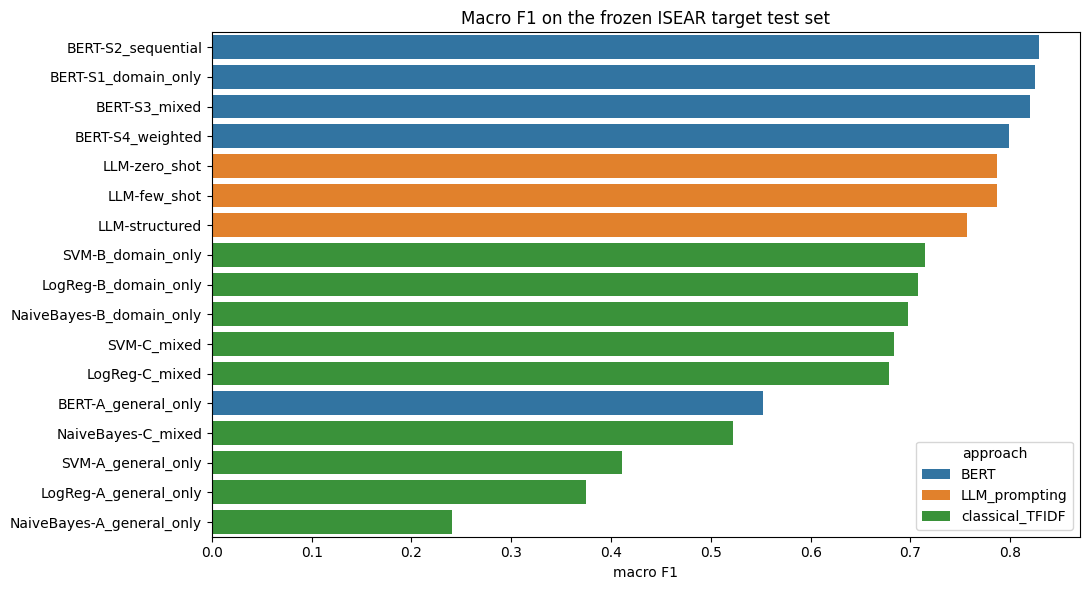

In [15]:
results_df = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
results_df.to_csv("results_comparison.csv", index=False)
pd.set_option("display.width", 200)
display(results_df.round(3))

plt.figure(figsize=(11, 6))
sns.barplot(data=results_df, y="model", x="f1", hue="approach", dodge=False)
plt.title("Macro F1 on the frozen ISEAR target test set"); plt.xlabel("macro F1"); plt.ylabel("")
plt.tight_layout(); plt.show()

### The A / B / C pattern visible
Compare, within each architecture, A (general only), B (domain only) and C (mixed). domain_gap = source-validation F1 − target-test F1 (how much a model loses when it moves to the target domain).

In [16]:
abc = results_df[results_df["model"].str.contains("A_general|B_domain|C_mixed|S1_domain|S3_mixed")]
display(abc[["model", "f1", "accuracy", "source_val_f1", "domain_gap"]].round(3))

,model,f1,accuracy,source_val_f1,domain_gap
1,BERT-S1_domain_only,0.825,0.825,0.573,-0.252
2,BERT-S3_mixed,0.820,0.821,0.964,0.144
7,SVM-B_domain_only,0.715,0.716,0.308,-0.407
8,LogReg-B_domain_only,0.708,0.708,0.295,-0.412
9,NaiveBayes-B_domain_only,0.698,0.697,0.302,-0.396
10,SVM-C_mixed,0.683,0.686,0.915,0.232
11,LogReg-C_mixed,0.679,0.680,0.865,0.186
12,BERT-A_general_only,0.552,0.551,0.962,0.410
13,NaiveBayes-C_mixed,0.522,0.546,0.619,0.096
14,SVM-A_general_only,0.411,0.435,0.918,0.507


## 8. Evaluation detail and error analysis

Best model by macro F1: BERT-S2_sequential 

              precision    recall  f1-score   support

       anger       0.77      0.77      0.77       217
        fear       0.85      0.84      0.84       216
         joy       0.92      0.93      0.92       216
     sadness       0.78      0.78      0.78       210

    accuracy                           0.83       859
   macro avg       0.83      0.83      0.83       859
weighted avg       0.83      0.83      0.83       859



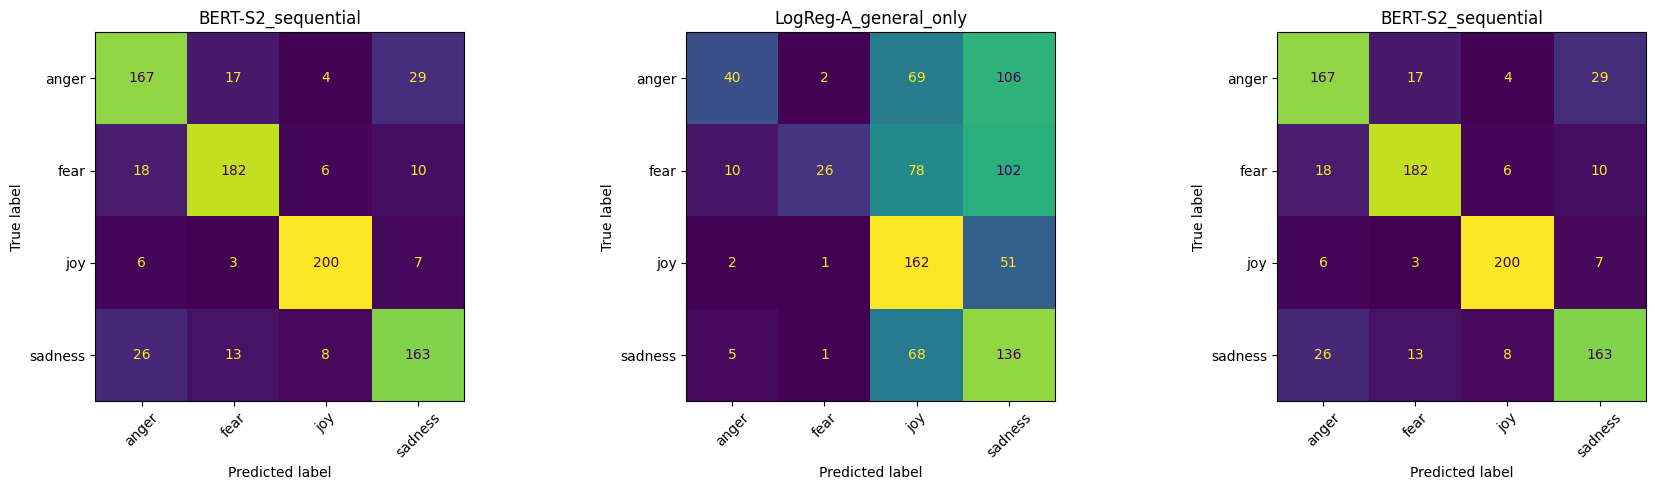

In [17]:
best = results_df.iloc[0]["model"]
print("Best model by macro F1:", best, "\n")
print(classification_report(target_test["label_mapped"], all_preds[best], labels=common_labels, zero_division=0))

def show_cm(name, ax):
    ConfusionMatrixDisplay.from_predictions(target_test["label_mapped"], all_preds[name], labels=common_labels,
                                            ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(name)

names = [best, "LogReg-A_general_only", "BERT-S2_sequential"]
fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 5))
for n, ax in zip(names, axes): show_cm(n, ax)
plt.tight_layout(); plt.show()

### Prediction failures: what does the general-only model get wrong on ISEAR?

In [18]:
err = target_test.assign(pred=all_preds["LogReg-A_general_only"])
err = err[err["label_mapped"] != err["pred"]]
print(f"{len(err)}/{len(target_test)} misclassified by LogReg Model A")
display(err[["clean", "label_mapped", "pred"]].sample(min(15, len(err)), random_state=SEED))

495/859 misclassified by LogReg Model A


,clean,label_mapped,pred
2197,when i had to walk home in the dark for the fi...,fear,joy
1848,my boyfriend hinted over the phone about wanti...,fear,joy
2740,when i was the target of a great many insults ...,anger,sadness
3670,when someone does something wrong which affect...,anger,sadness
949,one year when i went to a camp i was chased by...,fear,joy
4050,seeing this badly made questionnaire,anger,joy
374,this happened when i was selected to go to sec...,joy,sadness
1692,i had fear when i was left alone at the bus de...,fear,sadness
3521,a man in a car was following me when i went ru...,fear,joy
2238,when i received the acceptance letter from unz...,joy,sadness


### Domain vocabulary: words much more frequent in target than in source

In [19]:
from collections import Counter
def counts(s): return Counter(w for t in s for w in t.split())
ct, cs = counts(target_train["clean"]), counts(source_train["clean"])
nt, ns = sum(ct.values()), sum(cs.values())
rows = [(w, c, (c / nt) / ((cs.get(w, 0) + 1) / ns)) for w, c in ct.items() if c >= 30]
vocab = pd.DataFrame(rows, columns=["word", "target_count", "target/source_ratio"]).sort_values("target/source_ratio", ascending=False)
print("\nTop target-specific vocabulary:")
display(vocab.head(25))


Top target-specific vocabulary:


,word,target_count,target/source_ratio
143,didn't,98,456.368116
197,examination,61,284.065868
245,selected,33,76.837489
137,grandmother,35,54.329538
44,died,147,48.896584
111,university,95,34.030590
130,exam,88,31.523072
95,accident,59,30.528026
224,failed,51,29.687212
100,passed,115,25.501620


### Bias / class-disparity check: per-class recall for every model

In [23]:
recalls = {}
for name, preds in all_preds.items():
    _, r, _, _ = precision_recall_fscore_support(target_test["label_mapped"], preds, labels=common_labels, zero_division=0)
    recalls[name] = r
pd.DataFrame(recalls, index=common_labels).T.round(3).sort_values(common_labels[0], ascending=False)

,anger,fear,joy,sadness
BERT-S1_domain_only,0.788,0.829,0.912,0.771
BERT-A_general_only,0.783,0.343,0.574,0.500
BERT-S2_sequential,0.770,0.843,0.926,0.776
BERT-S3_mixed,0.747,0.852,0.926,0.757
BERT-S4_weighted,0.724,0.810,0.889,0.771
SVM-B_domain_only,0.705,0.736,0.810,0.610
LogReg-B_domain_only,0.705,0.741,0.773,0.610
NaiveBayes-B_domain_only,0.696,0.741,0.704,0.648
LLM-zero_shot,0.664,0.769,0.912,0.805
SVM-C_mixed,0.590,0.704,0.838,0.610
